# Análisis exploratorio (EDA) — BTC/USDT (sabana_trading_rl)

Este EDA tiene como objetivo entender las características de los datos que afectan al agente y **justificar** la elección de features, la partición temporal y el diseño de la recompensa.

> Ejecutar desde la raíz del repo o desde `notebooks/`. Requiere `data/BTCUSDT_1d.csv` (`python -m src.data`).

In [ ]:
# !/usr/bin/env python3

import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_prices, compute_features, build_splits, count_missing_bars
from src.metrics import drawdown_series
from src.utils import load_config

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
cfg = load_config(ROOT / "configs" / "base.yaml")
prices = load_prices(ROOT / cfg["data"]["csv"])
PPY = cfg["env"]["periods_per_year"]   # 365: cripto opera 24/7
SYM = cfg["data"]["symbol"]
splits = build_splits(prices, cfg["data"])
bounds = {k: tuple(pd.Timestamp(x) for x in v) for k, v in cfg["data"]["splits"].items()}
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
print(SYM, prices.shape, prices.index.min().date(), "->", prices.index.max().date())
print("Velas faltantes (huecos del exchange):", count_missing_bars(prices, cfg["data"]["download"]["timeframe"]))
print("Velas duplicadas:", int(prices.index.duplicated().sum()))
prices.head()

BTC/USDT (3059, 5) 2017-08-17 -> 2025-12-31
Velas faltantes (huecos del exchange): 0
Velas duplicadas: 0


,open,high,low,close,volume
timestamp,,,,,
2017-08-17,4261.48,4485.39,4200.74,4285.08,795.150377
2017-08-18,4285.08,4371.52,3938.77,4108.37,1199.888264
2017-08-19,4108.37,4184.69,3850.00,4139.98,381.309763
2017-08-20,4120.98,4211.08,4032.62,4086.29,467.083022
2017-08-21,4069.13,4119.62,3911.79,4016.00,691.743060


## 1. Evolución histórica del precio y partición temporal

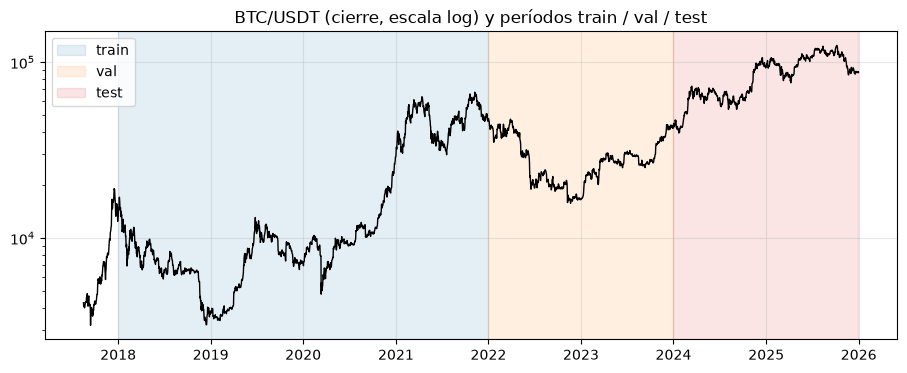

In [ ]:
# Grafico de precios y splits

fig, ax = plt.subplots()
ax.semilogy(prices.index, prices["close"], color="black", lw=1)
for k, (a, b) in bounds.items():
    ax.axvspan(a, b, color=colors[k], alpha=0.12, label=k)
ax.set_title(f"{SYM} (cierre, escala log) y períodos train / val / test")
ax.legend(); plt.show()

# recordar que la parte blanca es el warmup, que no se usa para entrenar ni evaluar. El agente ve la vela de cierre de cada barra, y decide al cierre de esa vela (con `close` ya conocido). La siguiente vela es la que se abre después del cierre de la barra actual.

## 2. Distribución de los retornos

            n  media_diaria  vol_anual  asimetria  curtosis_exceso  peor_dia  mejor_dia
train  1461.0        0.0008     0.7885    -1.3502          16.9135   -0.5026     0.1784
val     730.0       -0.0001     0.5519    -0.3943           5.2708   -0.1670     0.1353
test    731.0        0.0010     0.4752     0.2473           2.1990   -0.0893     0.1123


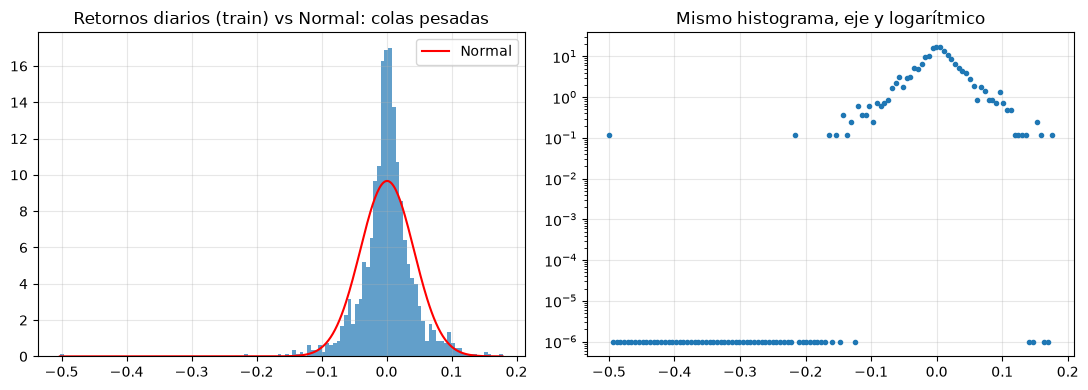

In [ ]:
# Estadísticas de los retornos diarios logarítmicos

ret = np.log(prices["close"]).diff().dropna()
rows = {}
for k, (a, b) in bounds.items():
    r = ret.loc[a:b]
    rows[k] = dict(n=len(r), media_diaria=r.mean(), vol_anual=r.std() * np.sqrt(PPY),
                   asimetria=r.skew(), curtosis_exceso=r.kurt(), peor_dia=r.min(), mejor_dia=r.max())
print(pd.DataFrame(rows).T.round(4).to_string())

fig, axes = plt.subplots(1, 2)
r = ret.loc[bounds["train"][0]:bounds["train"][1]]
axes[0].hist(r, bins=120, density=True, alpha=0.7)
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi)), "r", label="Normal")
axes[0].set_title("Retornos diarios (train) vs Normal: colas pesadas"); axes[0].legend()
h, edges = np.histogram(r, bins=120, density=True)
axes[1].semilogy((edges[:-1] + edges[1:]) / 2, h + 1e-6, ".")
axes[1].set_title("Mismo histograma, eje y logarítmico")
plt.tight_layout(); plt.show()

 

Vemos Curtosis alta + días extremos de +-10 %. Esto nos da retornos no normales.

Esto justifica plenamente penalizar drawdown (dd_coef) y no confiar solo en retorno medio

## 3. Períodos de alta y baja volatilidad

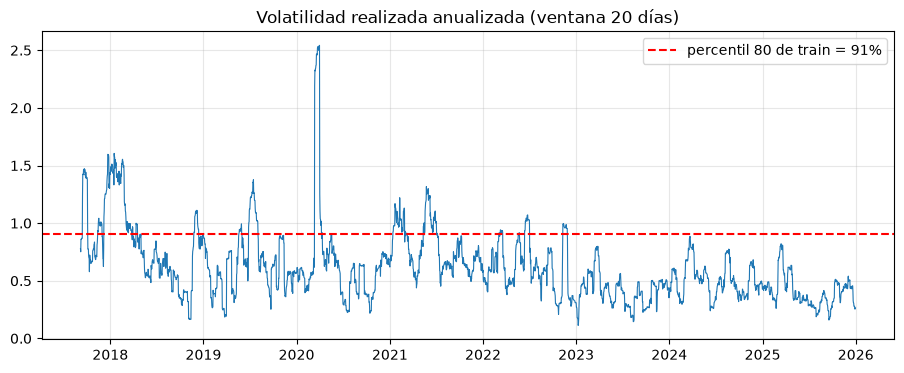

timestamp       2017   2018   2019   2020   2021   2022   2023   2024   2025
vol_anual      1.097  0.840  0.682  0.810  0.809  0.644  0.436  0.527  0.417
retorno_anual  1.163 -1.309  0.664  1.391  0.469 -1.027  0.938  0.794 -0.065


In [4]:

vol20 = ret.rolling(20).std() * np.sqrt(PPY)
thr = vol20.loc[bounds["train"][0]:bounds["train"][1]].quantile(0.8)
fig, ax = plt.subplots()
ax.plot(vol20.index, vol20, lw=0.8)
ax.axhline(thr, color="r", ls="--", label=f"percentil 80 de train = {thr:.0%}")
ax.set_title("Volatilidad realizada anualizada (ventana 20 días)"); ax.legend(); plt.show()

by_year = pd.DataFrame({"vol_anual": ret.groupby(ret.index.year).std() * np.sqrt(PPY),
                        "retorno_anual": ret.groupby(ret.index.year).sum()})
print(by_year.round(3).T.to_string())

La volatilidad realizada es muy variable entre años.

Hay clusters de alta volatilidad (2018, 2020, 2022).

Esto justifica tener features de volatilidad (vol_20, vol_ratio) y una penalización de riesgo en la recompensa.

## 4. Tendencias y caídas (drawdown del buy & hold)

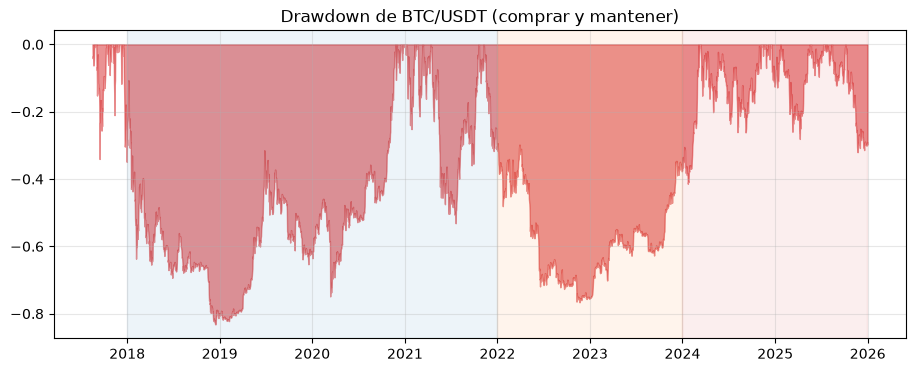

train: retorno +245.4% | máx. drawdown dentro del período -81.2%
  val: retorno -11.4% | máx. drawdown dentro del período -66.9%
 test: retorno +98.4% | máx. drawdown dentro del período -32.0%


In [5]:
dd = drawdown_series(prices["close"])
fig, ax = plt.subplots()
ax.fill_between(dd.index, dd, color="tab:red", alpha=0.5)
for k, (a, b) in bounds.items():
    ax.axvspan(a, b, color=colors[k], alpha=0.08)
ax.set_title(f"Drawdown de {SYM} (comprar y mantener)"); plt.show()
for k, (a, b) in bounds.items():
    seg = prices["close"].loc[a:b]
    print(f"{k:>5}: retorno {seg.iloc[-1] / seg.iloc[0] - 1:+.1%} | máx. drawdown dentro del período {drawdown_series(seg).min():.1%}")

Los drawdowns de buy & hold son grandes, pueden superar −60/−70%.

La hipótesis, sería que un agente que iguale el retorno de buy & hold con menor drawdown, podría ser más atractivo para un inversor. 

## 5. Volumen

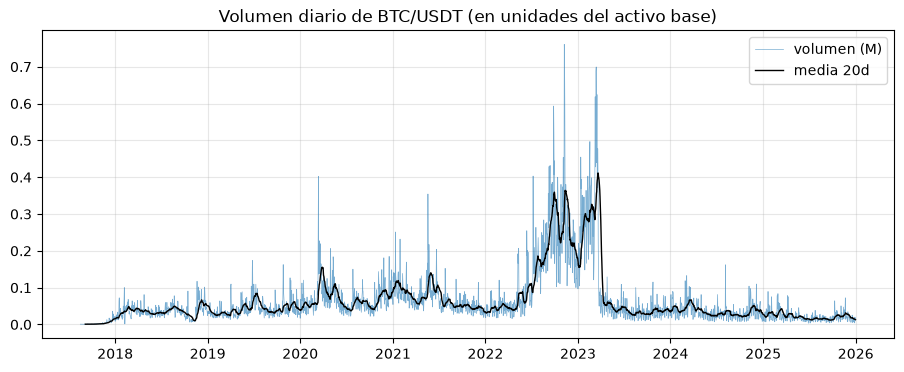

Correlación |retorno| vs vol_ratio: 0.442


In [6]:
fig, ax = plt.subplots()
ax.plot(prices.index, prices["volume"] / 1e6, lw=0.5, alpha=0.6, label="volumen (M)")
ax.plot(prices.index, prices["volume"].rolling(20).mean() / 1e6, color="k", lw=1, label="media 20d")
ax.set_title(f"Volumen diario de {SYM} (en unidades del activo base)"); ax.legend(); plt.show()
# ¿sube el volumen cuando el mercado cae?
rv = pd.DataFrame({"abs_ret": ret.abs(), "vol_ratio": np.log(prices["volume"] / prices["volume"].rolling(20).mean())}).dropna()
print("Correlación |retorno| vs vol_ratio:", round(rv.corr().iloc[0, 1], 3))

Hay correlación positiva entre |retorno| y vol_ratio -> el volumen sube en días movidos.

Justifica incluir vol_ratio como feature de actividad/liquidez.

## 6. Indicadores seleccionados

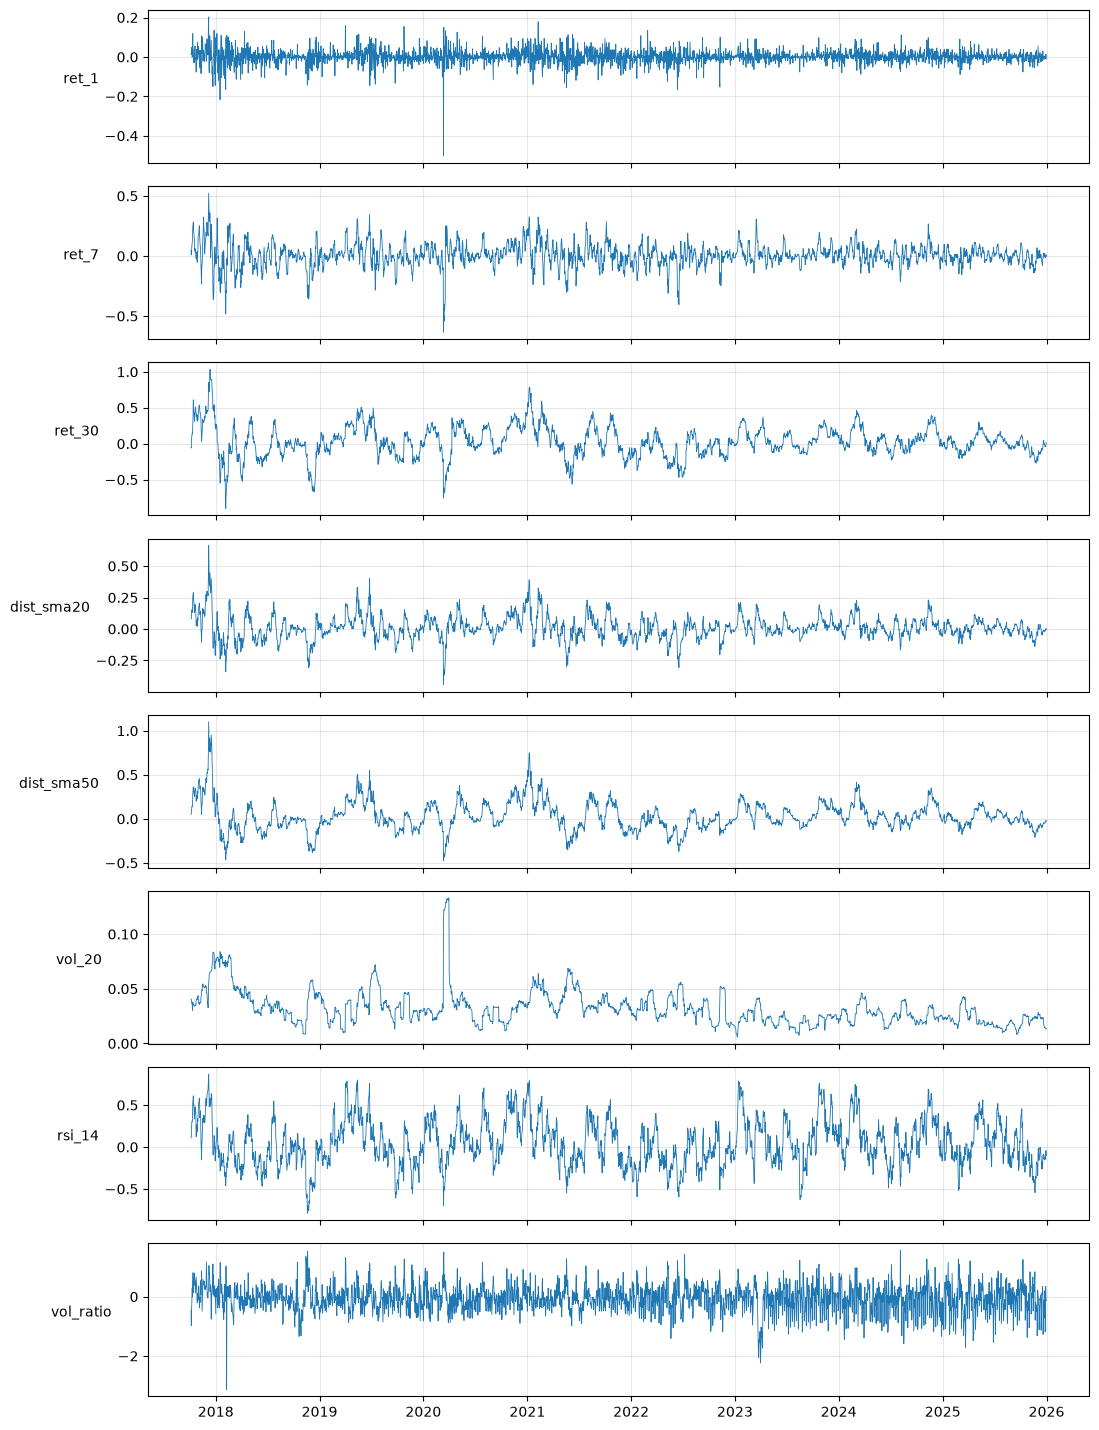

Estadísticos por período (features sin normalizar):
             ret_1   ret_7  ret_30  dist_sma20  dist_sma50  vol_20  rsi_14  vol_ratio
train mean  0.0008  0.0059  0.0245      0.0103      0.0290  0.0378  0.0444    -0.0625
      std   0.0413  0.1085  0.2359      0.1028      0.1753  0.0177  0.2773     0.3907
val   mean -0.0001 -0.0012 -0.0057     -0.0003     -0.0023  0.0269  0.0110    -0.0926
      std   0.0289  0.0801  0.1636      0.0739      0.1202  0.0107  0.2785     0.4926
test  mean  0.0010  0.0069  0.0302      0.0101      0.0279  0.0238  0.0592    -0.1305
      std   0.0249  0.0626  0.1326      0.0595      0.1045  0.0076  0.2457     0.5244


In [7]:
raw = compute_features(prices)[cfg["data"]["features"]]
fig, axes = plt.subplots(len(raw.columns), 1, figsize=(11, 1.8 * len(raw.columns)), sharex=True)
for ax, c in zip(axes, raw.columns):
    ax.plot(raw.index, raw[c], lw=0.6); ax.set_ylabel(c, rotation=0, ha="right")
plt.tight_layout(); plt.show()

print("Estadísticos por período (features sin normalizar):")
print(pd.concat({k: raw.loc[a:b].describe().loc[["mean", "std"]] for k, (a, b) in bounds.items()}).round(4).to_string())

### Correlación entre features (redundancia) y relación con el retorno futuro

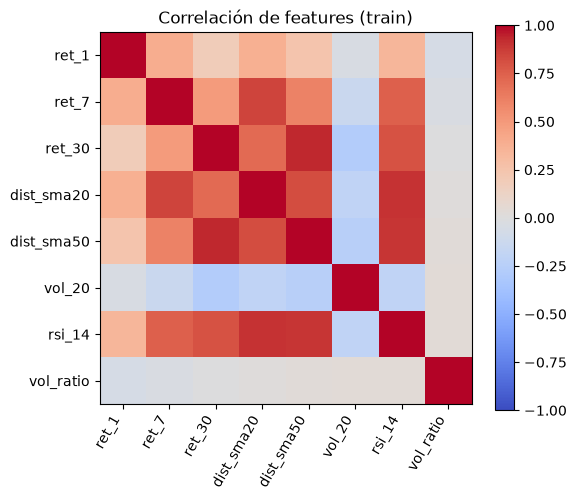

Correlación de Spearman feature_t vs retorno_{t+1} (train):
ret_1        -0.0788
vol_20        0.0080
ret_7         0.0107
dist_sma20    0.0156
ret_30        0.0246
dist_sma50    0.0272
rsi_14        0.0313
vol_ratio     0.0343


In [9]:
train_raw = raw.loc[bounds["train"][0]:bounds["train"][1]]
corr = train_raw.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
plt.colorbar(im); ax.set_title("Correlación de features (train)"); plt.show()

# SOLO ANÁLISIS: se usa el retorno de t+1 como etiqueta para medir poder predictivo.
# Esto NUNCA entra en el estado del agente.
fwd = np.log(prices["close"]).diff().shift(-1).reindex(train_raw.index)
ic = train_raw.apply(lambda s: s.corr(fwd, method="spearman")).sort_values()
print("Correlación de Spearman feature_t vs retorno_{t+1} (train):")
print(ic.round(4).to_string())

Las correlaciones con el retorno del día siguiente son muy pequeñas (señal débil);
por eso es normal que el agente no supere claramente a buy & hold.
En cripto los drawdowns de buy & hold son enormes (−70 % o más), así que las features de volatilidad y tendencia pueden ayudar a **gestionar el riesgo**, que es donde un agente puede aportar valor.

## 7. Cambio de régimen entre train y test (distribution shift)

In [10]:
z = pd.concat({k: s.features.describe().loc[["mean", "std"]] for k, s in splits.items()})
print("Features normalizadas con media/std de TRAIN. Si val/test se alejan de 0/1 hay cambio de régimen:")
print(z.round(2).to_string())

Features normalizadas con media/std de TRAIN. Si val/test se alejan de 0/1 hay cambio de régimen:
            ret_1  ret_7  ret_30  dist_sma20  dist_sma50  vol_20  rsi_14  vol_ratio
train mean   0.01   0.00   -0.00       -0.00       -0.00   -0.00    0.00       0.00
      std    0.96   1.00    1.00        1.00        1.00    0.99    1.00       0.99
val   mean  -0.02  -0.07   -0.13       -0.10       -0.18   -0.61   -0.12      -0.08
      std    0.70   0.74    0.69        0.72        0.69    0.60    1.00       1.26
test  mean   0.00   0.01    0.02       -0.00       -0.01   -0.79    0.05      -0.17
      std    0.60   0.58    0.56        0.58        0.60    0.43    0.89       1.34


Si las features normalizadas de val/test se alejan de media≈0 y std≈1, hay distribution shift.

Es normal y esperado. Confirma que no se puede confiar solo en el rendimiento de train y que la validación es imprescindible.

## 8. ¿Cuánto pesan los costos de transacción?

In [11]:
cost = cfg["env"]["cost_bps"] / 1e4
print(f"Costo por cambiar de 0 % a 100 %: {cost:.2%}")
print(f"Retorno medio diario (train): {ret.loc[bounds['train'][0]:bounds['train'][1]].mean():.3%}")
print(f"Movimiento absoluto medio diario:     {ret.abs().mean():.3%}")
print(f"Un ida y vuelta (0→100→0) cuesta {2 * cost:.2%}, equivalente a ~{2 * cost / ret.loc[bounds['train'][0]:bounds['train'][1]].mean():.1f} días de retorno medio.")

Costo por cambiar de 0 % a 100 %: 0.10%
Retorno medio diario (train): 0.083%
Movimiento absoluto medio diario:     2.379%
Un ida y vuelta (0→100→0) cuesta 0.20%, equivalente a ~2.4 días de retorno medio.


Un ida-y-vuelta (0→100→0) cuesta 0,20 %.

Eso equivale a varios días de retorno medio.

Por eso el turnover_penalty tiene sentido: sin él el agente tiende a sobre-operar y se come la rentabilidad.

## 9. Conclusiones

- **Estado:**  
  Las 8 features + posición actual son un conjunto razonable y no redundante en exceso.  
  La señal predictiva sobre el retorno del día siguiente es débil (correlaciones Spearman cercanas a 0), por lo que el agente no debería esperarse que **adivine** el mercado. El valor del agente está en la **gestión dinámica del riesgo** (reducir exposición en regímenes de alta volatilidad o tendencia bajista).

- **Partición temporal:**  
  La división train (2018-2021) / val (2022-2023) / test (2024-2025) busca ser coherente y cubre regímenes distintos para evitar cualquier data leakage.  
  Algo interesante, es que el período de test es el más alcista, por lo que los resultados en held-out tienden a ser más favorables que en validación. Esto debe tenerse en cuenta al interpretar el rendimiento final.

- **Recompensa:**  
  Los retornos no son normales (colas pesadas y días extremos).  
  Por tanto, maximizar solo el retorno logarítmico es insuficiente (ver DQN V1). Es necesario penalizar el aumento de drawdown y la rotación excesiva (V2 -> V3 -> V4).  
  Los costos de transacción (10 bps) son materialmente relevantes. Un ida y vuelta completo equivale a varios días de retorno medio, lo que justifica el `turnover_penalty`.

- **Riesgos de reward hacking anticipados:**  
  1. Quedarse siempre en cash (evitar cualquier drawdown).  
  2. Imitar buy & hold (exposición casi siempre al 100 %).  
  3. Sobre-operar para cazar pequeños movimientos (especialmente en V1).  
  Estos comportamientos se diagnostican con `positions.png` y las métricas de `pct_days_cash`, `avg_position` y `trades_per_year` en validación.